# Target Leakage Prevention

**Leakage** happens when a model is trained with information that will not be available when it makes real predictions. Leaky models look excellent in evaluation and fail in production. Leakage is the most expensive mistake in applied machine learning, because it is invisible in the metrics.

**After this lesson you can:**

1. Recognise feature leakage: features recorded after the event you predict.
2. Recognise preprocessing leakage: transformations fitted on test data.
3. Recognise split leakage: the same entity or future data in training and test.
4. Design evaluations that match how the model will be used.

**Data:** Bank Marketing (41,188 phone calls of a Portuguese bank, 2008–2010; target: did the client subscribe a term deposit?).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
RNG = 42

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, TimeSeriesSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

bank = datasets.bank_marketing()
y = (bank["y"] == "yes").astype(int)
print(bank.shape, "| subscription rate:", round(y.mean(), 3))
bank.head(3)

(41188, 21) | subscription rate: 0.113


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 1. Feature Leakage: `duration`

`duration` is the length of the phone call in seconds. It is strongly related to the outcome (a long call usually means interest). But the bank wants to decide **whom to call before calling**: at that moment, the duration is unknown. The dataset's documentation itself says the column should be dropped for a realistic model.

with duration (leaky)        ROC AUC 0.950
without duration (realistic) ROC AUC 0.805


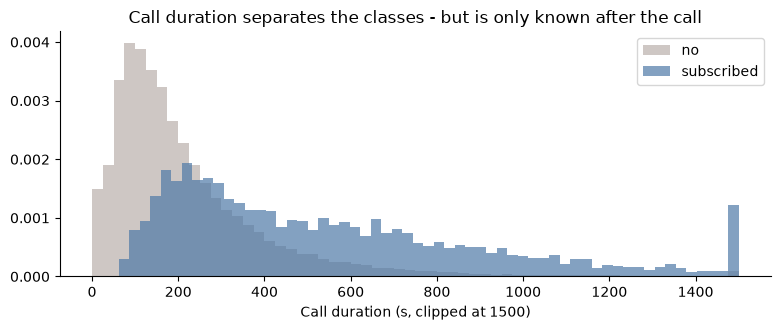

In [2]:
cat = bank.select_dtypes(include="str").columns.drop("y").tolist()
num_all = bank.select_dtypes("number").columns.tolist()
num_ok = [c for c in num_all if c != "duration"]
cv = StratifiedKFold(5, shuffle=True, random_state=RNG)

def model(num):
    pre = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return make_pipeline(pre, HistGradientBoostingClassifier(random_state=RNG))

auc_leak = cross_val_score(model(num_all), bank, y, cv=cv, scoring="roc_auc").mean()
auc_real = cross_val_score(model(num_ok), bank, y, cv=cv, scoring="roc_auc").mean()
print(f"with duration (leaky)        ROC AUC {auc_leak:.3f}")
print(f"without duration (realistic) ROC AUC {auc_real:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.4))
for lab, c in [(0, "#BAB0AC"), (1, "#4E79A7")]:
    ax.hist(bank.loc[y == lab, "duration"].clip(upper=1500), bins=60, alpha=0.7, density=True, color=c, label="subscribed" if lab else "no")
ax.set(title="Call duration separates the classes - but is only known after the call", xlabel="Call duration (s, clipped at 1500)")
ax.legend()
plt.tight_layout()
plt.show()

The leaky model looks much better, and it is useless: it needs the call to have happened. Ask for **every** feature: *at prediction time, would I know this value?* Typical leaky features: status fields updated after the event, totals that include the outcome, "date closed", IDs assigned by the downstream process.

## 2. Preprocessing Leakage

Fitting a scaler, imputer, encoder or feature selector on **all** data before cross-validation lets test-fold information into training. The effect is small for a scaler, and large for supervised steps such as feature selection or target encoding. The experiment adds 2,000 random noise columns and selects the 20 "best" ones, either before or inside the cross-validation.

In [3]:
rng = np.random.default_rng(RNG)
sample = bank.sample(3000, random_state=RNG)
ys = y.loc[sample.index]
noise = pd.DataFrame(rng.normal(size=(len(sample), 2000)), index=sample.index)

selected = SelectKBest(f_classif, k=20).fit(noise, ys).get_support()             # WRONG: uses all rows, incl. test folds
leaky = cross_val_score(LogisticRegression(max_iter=2000), noise.loc[:, selected], ys, cv=cv, scoring="roc_auc").mean()
clean = cross_val_score(make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=2000)), noise, ys, cv=cv,
                        scoring="roc_auc").mean()
print(f"pure noise, selection before CV : ROC AUC {leaky:.3f}  <- fake skill")
print(f"pure noise, selection inside CV : ROC AUC {clean:.3f}  <- correct (about 0.5)")

pure noise, selection before CV : ROC AUC 0.674  <- fake skill
pure noise, selection inside CV : ROC AUC 0.514  <- correct (about 0.5)


Put **every** fitted step inside a `Pipeline`, and pass the pipeline to cross-validation (Lesson 10).

## 3. Split Leakage: Entities and Time

A random split assumes every row is independent. Two common violations:

- **Groups:** several rows per customer, patient or house. If the same customer is in training and test, the model can memorise the customer. Use `GroupKFold`.
- **Time:** the model will predict the future, so test data must come **after** training data. A random split lets the model learn from the future. Use `TimeSeriesSplit` or a cut-off date.

The bank data is in **time order** (May 2008 to November 2010), and economic conditions changed strongly during the financial crisis. The cell compares a random split with a time-ordered split.

random 5-fold        : [0.799 0.803 0.818 0.798 0.805] mean 0.805
time-ordered 5 splits: [0.507 0.523 0.446 0.59  0.604] mean 0.534


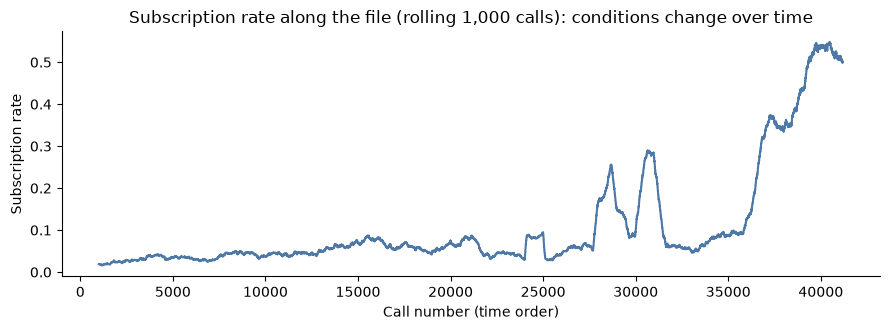

In [4]:
tscv = TimeSeriesSplit(n_splits=5)
random_auc = cross_val_score(model(num_ok), bank, y, cv=cv, scoring="roc_auc")
time_auc = cross_val_score(model(num_ok), bank, y, cv=tscv, scoring="roc_auc")
print("random 5-fold        :", random_auc.round(3), "mean", random_auc.mean().round(3))
print("time-ordered 5 splits:", time_auc.round(3), "mean", time_auc.mean().round(3))

fig, ax = plt.subplots(figsize=(9, 3.4))
roll = y.rolling(1000).mean()
ax.plot(range(len(y)), roll, color="#4E79A7")
ax.set(title="Subscription rate along the file (rolling 1,000 calls): conditions change over time",
       xlabel="Call number (time order)", ylabel="Subscription rate")
plt.tight_layout()
plt.show()

The time-ordered evaluation is lower and much more variable: the model must predict periods whose conditions it has not seen. That is the honest estimate for a model that will be used on next month's calls.

## 4. A Leakage Checklist

| Question | If yes |
| :--- | :--- |
| Is any feature recorded after the moment of prediction? | remove it, or rebuild it "as of" the prediction time |
| Does any feature use the target (target encoding, aggregates over outcomes)? | compute it out-of-fold / only from the past |
| Is any transformation fitted outside the cross-validation? | move it into the pipeline |
| Can the same entity appear in training and test? | `GroupKFold`, split by entity |
| Will the model predict the future? | time-based split, no future data in features |
| Is the score "too good to be true"? | inspect the most important features first |

*Insight: For every feature and every preprocessing step, ask "would I have this information at the moment of prediction?", and evaluate with a split that mimics production (groups, time). A model with slightly lower but honest scores is worth far more than a leaky model.*

## Real-World Use Case or Analogy

Leakage is like a **student who sees the exam answers** while practising: excellent practice scores, failure in the real exam. The danger is that nobody notices until the real exam.

Well-known cases include medical models that learned the hospital's scanner type or a "patient was treated" field instead of the disease, and competitions where a row id or a timestamp gave away the label. Kaggle calls the most dramatic cases "leaks" and often has to restart competitions because of them.